# Análisis de mercado: ¿qué sectores de EE.UU. ganaron la década 2015-2025?

**Pregunta guía:** ¿cómo se comportaron los grandes sectores de la bolsa estadounidense frente al índice S&P 500 (SPY) y a cuánto riesgo se expuso quien los eligió?

Usamos 15 acciones de 5 sectores más el ETF `SPY`, precios diarios ajustados (dividendos y splits) de Yahoo Finance. Cada sector es una cartera de **igual ponderación** de sus acciones (rebalanceada a diario, por simplicidad).

La historia tiene cuatro actos: (1) quién rindió más, (2) a qué costo de volatilidad, con dos shocks — COVID 2020 y alza de tasas 2022, (3) cuánto dolieron las caídas y (4) si diversificar entre sectores realmente protegió.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src import data as d

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titleweight": "bold"})
PALETTE = dict(zip(d.SECTORS, sns.color_palette("tab10", len(d.SECTORS))))
PALETTE["Índice"] = "black"

prices = d.load_prices()
rets = d.daily_returns(prices)
# Carteras sectoriales de igual ponderación
sector_rets = pd.DataFrame({s: rets[ts].mean(axis=1) for s, ts in d.SECTORS.items()})
sector_idx = (1 + sector_rets).cumprod()
print(f"{prices.shape[0]} días, {prices.shape[1]} tickers, {prices.index.min():%Y-%m-%d} a {prices.index.max():%Y-%m-%d}")

2765 días, 16 tickers, 2015-01-02 a 2025-12-30


## 1. Rendimiento acumulado por sector vs SPY

Escala logarítmica: así una línea recta equivale a crecimiento compuesto constante y se pueden comparar sectores muy distintos.

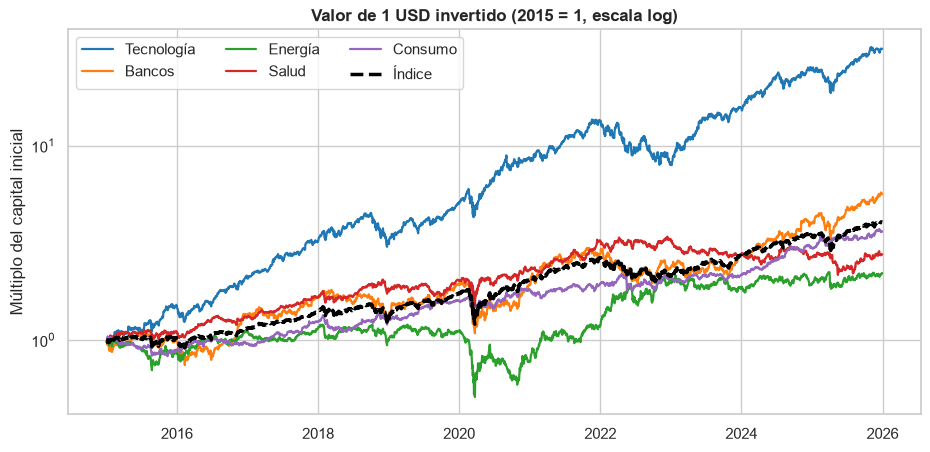

Tecnología    3042 %
Bancos         461 %
Índice         303 %
Consumo        261 %
Salud          175 %
Energía        121 %
Name: 2025-12-30 00:00:00, dtype: str


In [2]:
cum = sector_idx - 1
fig, ax = plt.subplots()
for s in cum:
    ax.plot(cum.index, 1 + cum[s], label=s, color=PALETTE[s],
            lw=2.5 if s == "Índice" else 1.6, ls="--" if s == "Índice" else "-")
ax.set_yscale("log")
ax.set_title("Valor de 1 USD invertido (2015 = 1, escala log)")
ax.set_ylabel("Múltiplo del capital inicial")
ax.legend(ncol=3)
plt.show()

final = cum.iloc[-1].sort_values(ascending=False)
print((final * 100).round(0).astype(int).astype(str) + " %")

**Lectura:** Tecnología se despega con claridad: su cartera multiplicó el capital ~30 veces (+3.000 %), frente a ~4 veces del SPY (+300 %). Bancos (~5,6×) también supera al índice, mientras que **Consumo, Salud y Energía quedan por debajo**. Ojo: el resultado tecnológico está muy sesgado por NVIDIA (+38.700 % individual), y es un sesgo de supervivencia — elegimos hoy a los ganadores de ayer.

### Retorno anual por sector

La tabla muestra cómo el liderazgo rota año a año: lo que gana un año no suele repetirse el siguiente.

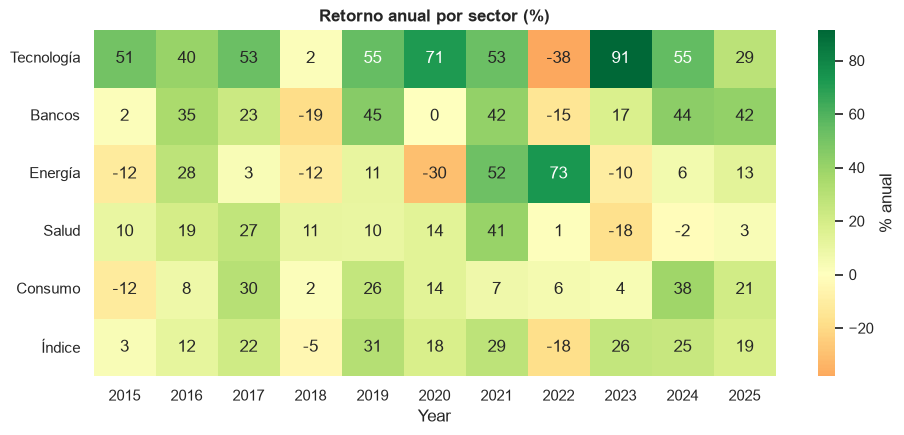

In [3]:
ann = d.annual_returns(sector_idx)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(ann.T * 100, annot=True, fmt=".0f", cmap="RdYlGn", center=0, cbar_kws={"label": "% anual"}, ax=ax)
ax.set_title("Retorno anual por sector (%)")
plt.show()

## 2. Volatilidad y eventos: COVID 2020 y alza de tasas 2022

Medimos la volatilidad móvil anualizada de 21 días del SPY y de los sectores, y marcamos los dos grandes shocks del periodo.

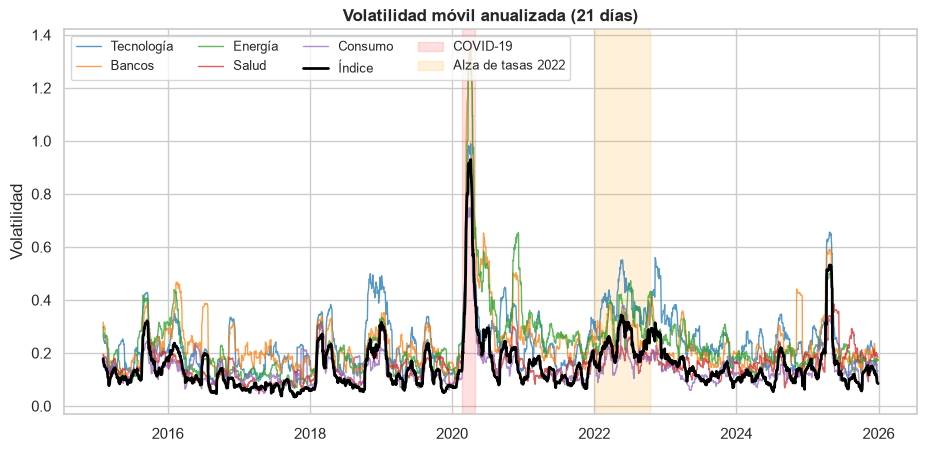

Pico de volatilidad SPY: 93% el 2020-04-06
Pico en 2022: 34%  |  Pico desde 2024: 53% (aranceles, abril 2025)


In [4]:
vol = d.rolling_volatility(sector_rets)
fig, ax = plt.subplots()
for s in vol:
    ax.plot(vol.index, vol[s], label=s, color=PALETTE[s], lw=2 if s == "Índice" else 1, alpha=1 if s == "Índice" else .75)
ax.axvspan("2020-02-19", "2020-04-30", color="red", alpha=.12, label="COVID-19")
ax.axvspan("2022-01-03", "2022-10-12", color="orange", alpha=.15, label="Alza de tasas 2022")
ax.set_title("Volatilidad móvil anualizada (21 días)")
ax.set_ylabel("Volatilidad")
ax.legend(ncol=4, fontsize=9)
plt.show()

spy_vol = d.rolling_volatility(rets["SPY"])
print(f"Pico de volatilidad SPY: {spy_vol.max():.0%} el {spy_vol.idxmax():%Y-%m-%d}")
print(f"Pico en 2022: {spy_vol.loc['2022'].max():.0%}  |  Pico desde 2024: {spy_vol.loc['2024':].max():.0%} (aranceles, abril 2025)")

**Lectura:** la volatilidad del SPY pasó de ~10-15 % en calma a **~93 % en abril de 2020**, un pico de otra escala. En 2022 el estrés fue más lento y prolongado (pico ~34 %). En abril de 2025 vuelve a dispararse (~53 % en el SPY) con el anuncio de aranceles. Energía y Bancos son los sectores más volátiles en promedio, junto a Tecnología.

Veamos cómo reaccionó cada acción en ambos eventos:

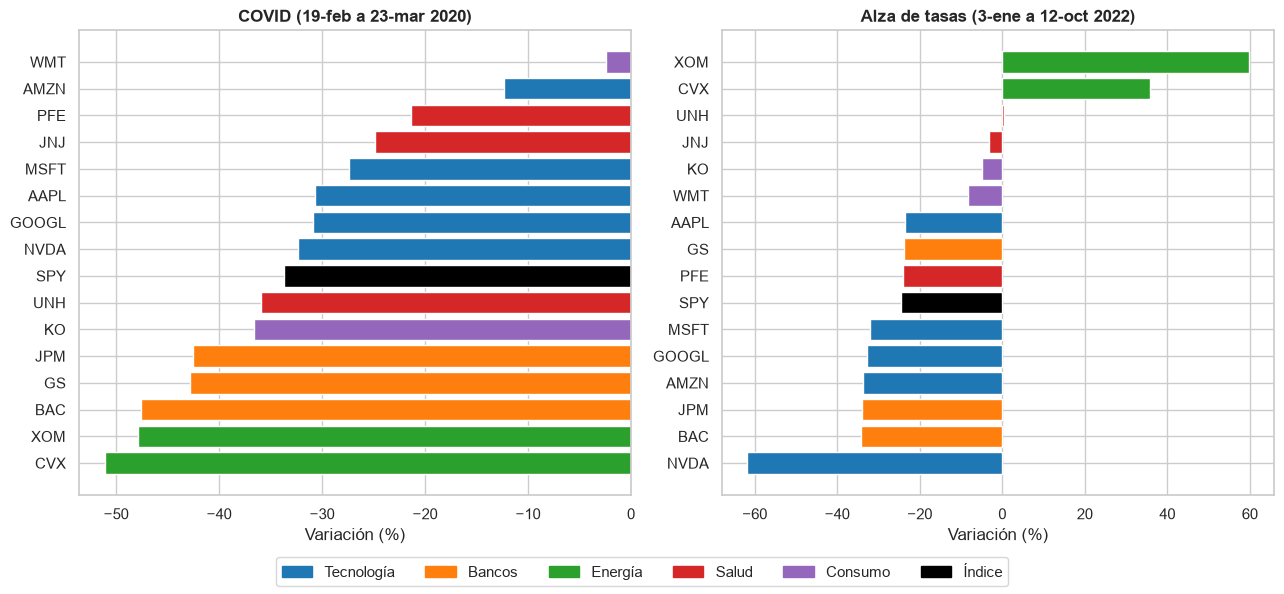

In [5]:
events = {"COVID (19-feb a 23-mar 2020)": ("2020-02-19", "2020-03-23"),
          "Alza de tasas (3-ene a 12-oct 2022)": ("2022-01-03", "2022-10-12")}
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=False)
for ax, (name, (a, b)) in zip(axes, events.items()):
    seg = prices.loc[a:b]
    chg = (seg.iloc[-1] / seg.iloc[0] - 1).sort_values()
    colors = [PALETTE[d.TICKER_TO_SECTOR[t]] for t in chg.index]
    ax.barh(chg.index, chg * 100, color=colors)
    ax.set_title(name)
    ax.set_xlabel("Variación (%)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in PALETTE.values()]
fig.legend(handles, PALETTE.keys(), loc="lower center", ncol=6)
plt.tight_layout(rect=(0, .05, 1, 1))
plt.show()

**Lectura:** el COVID fue un golpe **indiscriminado**: casi todo cayó entre 20 % y 50 % (Energía y Bancos hasta -50 %), salvo defensivas como Walmart (-2 %) o Amazon (-12 %). En 2022 el patrón fue distinto: **Energía subió (XOM +60 %, CVX +36 %)** mientras la tecnología de crecimiento sufría (NVDA -62 %) por el alza de tasas. Es la mejor evidencia de que diversificar entre sectores sí cambia el resultado en un régimen inflacionario.

## 3. Drawdowns: cuánto duele el camino

El *drawdown* mide la caída desde el máximo previo. Es lo que realmente se siente al invertir, más que la volatilidad.

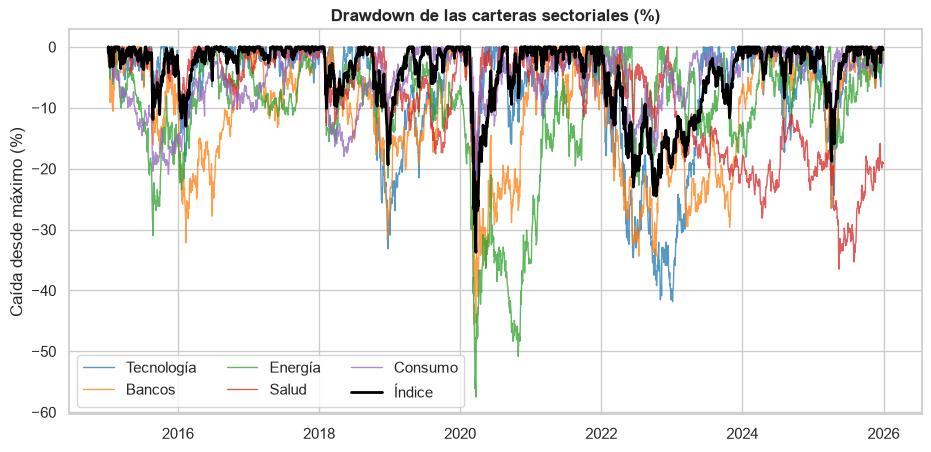

Energía       -57.5 %
Bancos        -45.3 %
Tecnología    -41.8 %
Salud         -36.5 %
Índice        -33.7 %
Consumo       -21.6 %
dtype: str


In [6]:
dd = d.drawdown_series(sector_idx)
fig, ax = plt.subplots()
for s in dd:
    ax.plot(dd.index, dd[s] * 100, label=s, color=PALETTE[s], lw=2 if s == "Índice" else 1, alpha=1 if s == "Índice" else .75)
ax.set_title("Drawdown de las carteras sectoriales (%)")
ax.set_ylabel("Caída desde máximo (%)")
ax.legend(ncol=3)
plt.show()

mdd = d.max_drawdown(sector_idx).sort_values()
print((mdd * 100).round(1).astype(str) + " %")

**Lectura:** el peor tramo lo vivió **Energía (-57 %)**, seguido de Bancos (-45 %) y Tecnología (-42 %); el SPY cayó -34 % y **Consumo fue el más resistente (-22 %)**. Tecnología rinde más pero con caídas más profundas que el índice: el premio por riesgo existe, pero se paga con paciencia.

## 4. Correlaciones: ¿diversificar funcionó?

Si los sectores se mueven juntos, la diversificación aporta poco. Medimos la correlación de retornos diarios.

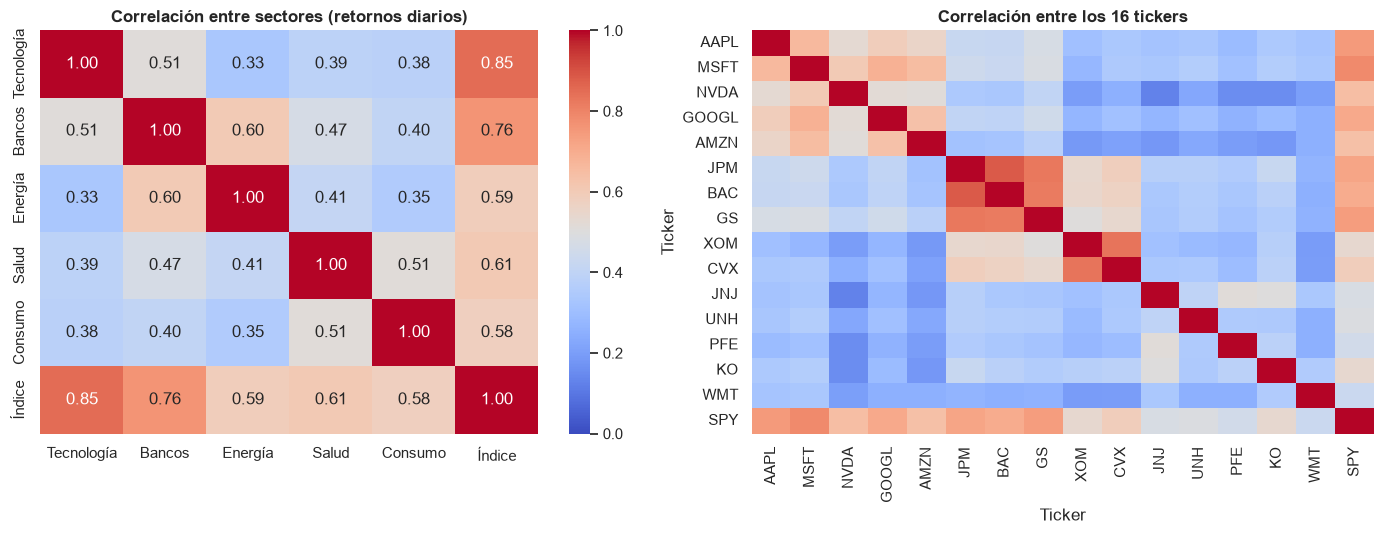

Correlación media entre pares: 2015-2019 = 0.40  |  2020-2022 = 0.51


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(sector_rets.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Correlación entre sectores (retornos diarios)")
sns.heatmap(rets.corr(), cmap="coolwarm", vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Correlación entre los 16 tickers")
plt.tight_layout()
plt.show()

calm = rets.loc["2015":"2019"].corr().values[np.triu_indices(16, 1)].mean()
stress = rets.loc["2020":"2022"].corr().values[np.triu_indices(16, 1)].mean()
print(f"Correlación media entre pares: 2015-2019 = {calm:.2f}  |  2020-2022 = {stress:.2f}")

**Lectura:** Tecnología es el sector que más se parece al mercado (0,85 con SPY, lógico dado su peso en el índice). Los menos correlacionados entre sí son Tecnología-Energía (0,33) y Consumo con Tecnología/Energía (~0,35-0,38). Además, **en las crisis (2020-2022) la correlación media entre pares sube de 0,40 a 0,51**: justo cuando más se necesita, la diversificación protege menos.

## 5. Riesgo vs retorno: Sharpe

El ratio de Sharpe (retorno anualizado dividido por volatilidad, con tasa libre de riesgo = 0 por simplicidad) indica cuánto retorno se obtiene por unidad de riesgo.

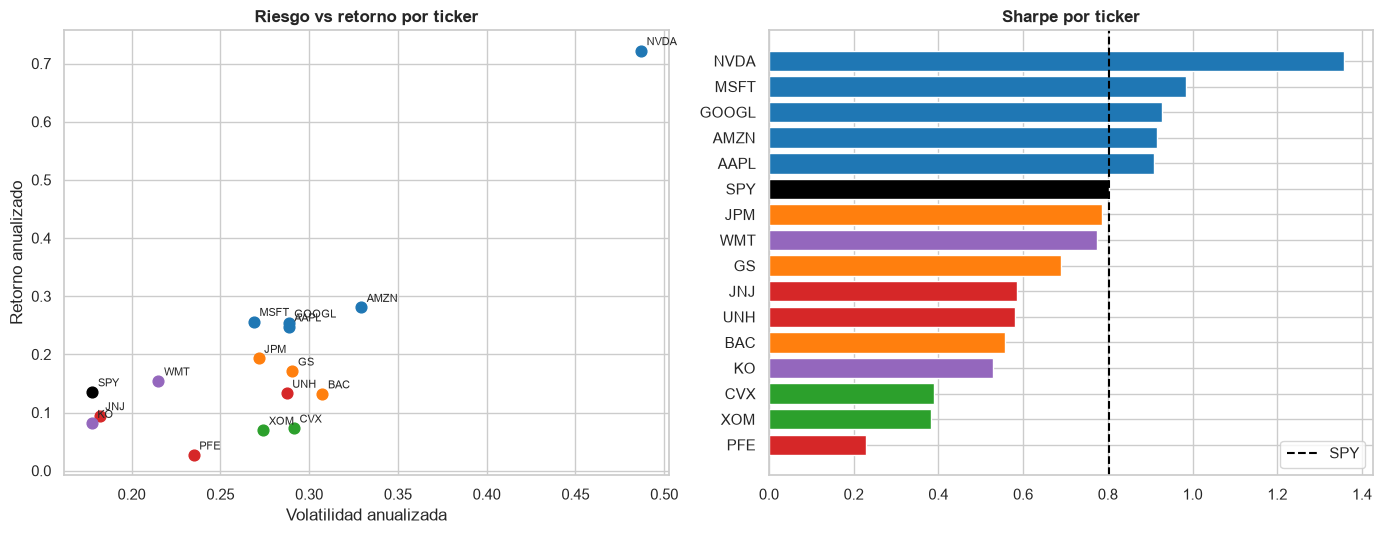

,ret,vol,sharpe
Tecnología,36.9%,27.2%,1.29
Consumo,12.4%,16.2%,0.80
Índice,13.5%,17.8%,0.80
Bancos,17.0%,27.4%,0.71
Salud,9.7%,18.4%,0.59
Energía,7.5%,27.1%,0.40


In [8]:
rr = pd.DataFrame({"ret": d.annualized_return(sector_rets), "vol": d.annualized_volatility(sector_rets),
                   "sharpe": d.sharpe_ratio(sector_rets)})
tick = d.summary_table(prices)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
for t in tick.index:
    ax.scatter(tick.loc[t, "Volatilidad"], tick.loc[t, "Retorno anualizado"],
               color=PALETTE[d.TICKER_TO_SECTOR[t]], s=60)
    ax.annotate(t, (tick.loc[t, "Volatilidad"], tick.loc[t, "Retorno anualizado"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Volatilidad anualizada"); ax.set_ylabel("Retorno anualizado")
ax.set_title("Riesgo vs retorno por ticker")

sh = tick["Sharpe"].sort_values()
axes[1].barh(sh.index, sh, color=[PALETTE[d.TICKER_TO_SECTOR[t]] for t in sh.index])
axes[1].axvline(tick.loc["SPY", "Sharpe"], color="black", ls="--", label="SPY")
axes[1].set_title("Sharpe por ticker"); axes[1].legend()
plt.tight_layout(); plt.show()

display(rr.sort_values("sharpe", ascending=False).style.format({"ret": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}"}))

**Lectura:** Tecnología lidera el Sharpe (1,29) frente a 0,80 del SPY y Consumo: es decir, **su mayor retorno compensó de sobra su riesgo**. Salud y Energía quedan por debajo (0,59 y 0,40): asumieron riesgo comparable al mercado (Energía, incluso mayor) con peor retorno. A nivel de acción, NVDA (1,36) destaca; PFE (0,23) y XOM/CVX (~0,38) son las peores relaciones riesgo-retorno.

## Conclusiones

1. **Tecnología dominó la década**: ~30× el capital inicial vs ~4× del SPY, con el mejor Sharpe (1,29). Pero parte del resultado es sesgo de supervivencia y concentración en NVDA.
2. **Más retorno implicó más dolor**: Tecnología cayó más que el índice en sus peores momentos (-42 % vs -34 %); Consumo fue el refugio (-22 %) con Sharpe igual al del SPY.
3. **Los shocks son distintos**: el COVID (volatilidad SPY ~93 %) hundió casi todo; en el alza de tasas de 2022 Energía subió mientras la tecnología caía. Diversificar por sector ayudó en 2022, no en 2020.
4. **La diversificación flaquea en las crisis**: la correlación media entre acciones sube de 0,40 (2015-19) a 0,51 (2020-22).
5. **Energía y Salud destruyeron valor relativo**: Sharpe de 0,40 y 0,59 frente a 0,80 del mercado, con caídas máximas de -57 % y -37 %.

> *Limitaciones:* universo reducido de 15 acciones elegidas hoy (sesgo de supervivencia), tasa libre de riesgo = 0 y rebalanceo diario sin costos de transacción. Esto es un análisis descriptivo, no una recomendación de inversión.